In [1]:
import os
os.environ["KERAS_BACKEND"]="torch"

In [2]:
import time
import keras
import matplotlib.pyplot as plt
from keras import layers, ops
import numpy as np
from PIL import Image
from keras.applications.inception_v3 import InceptionV3, preprocess_input
import torch
import gc
import json
import collections
from pathlib import Path
from tqdm.auto import tqdm
import shutil
import numpy as np
from PIL import Image
import tensorflow as tf
from sklearn.utils import shuffle

# Chemins et imports
Le notebook sélectionne le backend Torch avant d’importer Keras. Il cherche le dossier models à partir du répertoire de travail, puis définit les chemins des modèles et des données.

In [3]:
PROJECT_DIR = os.path.abspath(os.getcwd())
MODELS_DIR = os.path.join(PROJECT_DIR, "models")
CLASSIFIER_WEIGHTS = os.path.join(MODELS_DIR, "model_full.weights.h5")
DENOISER_MODEL = os.path.join(MODELS_DIR, "unet_denoiser_livrable2.keras")
DATASETS_DIR = os.path.join(PROJECT_DIR, "datasets", "Livrable 3")
COCO_DIR = os.path.join(DATASETS_DIR, "train2014")
PHOTOS_DIR = os.path.join(DATASETS_DIR, "photos")
DENOISED_DIR = os.path.join(DATASETS_DIR, "denoised_images")
ANNOTATIONS_DIR = os.path.join(DATASETS_DIR, "annotations")
ANNOTATION_FILE = os.path.join(ANNOTATIONS_DIR, "captions_train2014.json")

# Etape 1 : classification Photo / Non-photo
Le modèle du livrable 1 reconnaît cinq classes : Painting, Photo, Schematics, Sketch et Text. Il faut donc garder ses cinq sorties : l’étape est dite binaire parce qu’on transforme ensuite sa prédiction en deux groupes, Photo et Non-photo.

Pour chaque image, le code :

la redimensionne en 128 × 128 ;
la passe au modèle, qui divise ses pixels par 255 grâce à sa couche Rescaling ;
récupère la probabilité associée à Photo ;
la compare au seuil 0,2301, défini dans le livrable 1.
Si la probabilité atteint le seuil, l’image est considérée comme une photo. Sinon, elle reste dans son dossier d’origine. Le code déplace les photos retenues dans datasets/photos — il ne les copie pas — mais ne déplace pas et ne supprime pas les autres images.

In [4]:
CLASS_NAMES = ["Painting", "Photo", "Schematics", "Sketch", "Text"]
NUM_CLASSES = len(CLASS_NAMES)
PHOTO_CLASS_INDEX = CLASS_NAMES.index("Photo")
THRESHOLD = 0.2301

In [5]:
def load_classifier_model():
    model = keras.models.load_model(CLASSIFIER_WEIGHTS, compile=False)
    return model

def load_image_as_array(path, target_size=(128, 128)):
    with Image.open(path) as image:
        image = image.convert("RGB").resize(target_size)
        return np.asarray(image, dtype=np.float32)

def classify_images(image_dir: str | Path,classifier: keras.models.Model):
    results = []
    image_dir = Path(image_dir)

    for image_file in tqdm(image_dir.iterdir()):
        image_array = load_image_as_array(str(image_file))
        image_array = np.expand_dims(image_array, axis=0)

        probabilities = classifier.predict(image_array,verbose=0)
        proba_photo = float(probabilities[0][PHOTO_CLASS_INDEX])

        results.append((str(image_file),proba_photo,proba_photo >= THRESHOLD))

    return results

def move_photos_to_folder(classification_results, dest_dir=PHOTOS_DIR):
    os.makedirs(dest_dir, exist_ok=True)
    moved = []
    for path, _, is_photo in classification_results:
        if is_photo:
            if os.path.abspath(os.path.dirname(path)) != os.path.abspath(dest_dir):
                filename = os.path.basename(path)
                dest_path = os.path.join(dest_dir, filename)
                if os.path.exists(dest_path):
                    base, extension = os.path.splitext(filename)
                    suffix = 1
                    while os.path.exists(dest_path):
                        dest_path = os.path.join(dest_dir, f"{base}_{suffix}{extension}")
                        suffix += 1
                shutil.move(path, dest_path)
                path = dest_path
            moved.append(path)
    return moved

# Etape 2 : débruitage avec le U-Net du livrable 2
Chaque photo retenue est chargée en RGB, redimensionnée en 299 × 299 et convertie en valeurs entre 0 et 1. Le U-Net du livrable 2 est ensuite appliqué à l’image, et le résultat est sauvegardé dans datasets/denoised_images.

Le U-Net effectue des opérations de pooling qui nécessitent des dimensions compatibles avec des réductions par deux. Le code complète donc temporairement les dimensions de 299 à 300, puis recadre le résultat à 299 × 299 avant de le sauvegarder.

In [6]:
def load_denoiser_model():
    denoiser = keras.models.load_model(DENOISER_MODEL, compile=False)
    return denoiser

def load_image_for_denoiser(path, target_size=(299, 299)):
    with Image.open(path) as image:
        image = image.convert("RGB").resize(target_size)
        return np.asarray(image, dtype=np.float32) / 255.0

def denoise_images(image_paths, denoiser, output_dir=DENOISED_DIR):
    os.makedirs(output_dir, exist_ok=True)

    for path in tqdm(image_paths):
        arr = load_image_for_denoiser(path)
        height, width = arr.shape[:2]
        pad_height = (-height) % 4
        pad_width = (-width) % 4
        padded = np.pad(arr, ((0, pad_height), (0, pad_width), (0, 0)), mode="edge")
        batch = np.expand_dims(padded, axis=0)
        denoised = keras.ops.convert_to_numpy(denoiser(batch, training=False))[0]
        denoised = denoised[:height, :width, :]
        denoised = np.clip(denoised, 0.0, 1.0)

        denoised_img = Image.fromarray(np.rint(denoised * 255).astype("uint8"))
        filename = os.path.basename(path)
        out_path = os.path.join(output_dir, filename)
        denoised_img.save(out_path)
        gc.collect()
        torch.cuda.empty_cache()


# Etape 3: Chargement des données

## Création des vecteurs captions et images

In [7]:
def create_captions_and_path_vectors(annotation_file):
    image_path_to_caption = collections.defaultdict(list)
    train_captions = []
    img_name_vector = []
    mark_start, mark_end = '<start> ', ' <end>'

    with open(annotation_file, 'r') as f:
        annotations = json.load(f)

    for val in annotations['annotations']:
        caption =  mark_start + val['caption'].strip() + mark_end
        image_path = os.path.join(DENOISED_DIR,'COCO_train2014_' + '%012d.jpg' % (val['image_id']) +'.npy')

        if not os.path.isfile(image_path):
            continue
        image_path_to_caption[image_path].append(caption)

    train_image_paths = list(image_path_to_caption.keys())


    for image_path in train_image_paths:
        caption_list = image_path_to_caption[image_path]
        train_captions.extend(caption_list)
        [img_name_vector.append(image_path) for _ in range(len(caption_list))]

    return img_name_vector, train_captions

## Prétraitement des annotations

In [8]:
def calc_max_length(tensor):
    return max(len(t) for t in tensor)

def annotation_preprocessing(train_captions, top_k=5000):
    tokenizer = tf.keras.preprocessing.text.Tokenizer(num_words=top_k,
                                                    oov_token="<unk>",
                                                    filters='!"#$%&()*+.,-/:;=?@[\\]^_`{|}~')

    tokenizer.fit_on_texts(train_captions)
    tokenizer.word_index['<pad>'] = 0
    tokenizer.index_word[0] = '<pad>'
    train_seqs = tokenizer.texts_to_sequences(train_captions)
    cap_vector = keras.preprocessing.sequence.pad_sequences(train_seqs, padding='post')
    max_length = calc_max_length(train_seqs)

    return cap_vector, max_length, tokenizer

# Etape 4: Extraction des caractéristiques avec InceptionV3

In [9]:
def build_inception_feature_extractor():
    # Charge InceptionV3 pré-entraîné sur ImageNet, sans la tête de classification
    image_model = InceptionV3(weights="imagenet", include_top=False)
    new_input = keras.Input(shape = (299, 299, 3))
    hidden_layer = image_model(new_input)

    return keras.Model(new_input, hidden_layer)

def load_image_for_inception(path, target_size=(299, 299)):
    img = tf.io.read_file(path)
    img = tf.image.decode_jpeg(img, channels=3)
    img = tf.image.resize(img, target_size)
    img = (img / 127.5) - 1.0

    return img, path

def extract_and_save_inception_features(img_name_vector, feature_extractor, batch_size=8):
    encode_train = sorted(set(img_name_vector))

    image_dataset = tf.data.Dataset.from_tensor_slices(encode_train)
    image_dataset = image_dataset.map(
    load_image_for_inception, num_parallel_calls=1).batch(batch_size)

    with torch.inference_mode():
        for img, path in tqdm(image_dataset):
            batch_features = feature_extractor(img, training=False)
            batch_features = keras.ops.reshape(batch_features,
                                        (batch_features.shape[0], -1, batch_features.shape[3]))
            for bf, p in zip(batch_features, path):
                bactch_feature = keras.ops.convert_to_numpy(bf)
                path_of_feature = p.numpy().decode("utf-8")
                np.save(path_of_feature, bactch_feature)

            del img
            del path
            del batch_features

            if torch.cuda.is_available():
                torch.cuda.empty_cache()


# Etape 5 : séparation train / validation (80/20)

In [10]:
def map_func(img_name, cap):
    img_tensor = np.load(img_name.decode('utf-8'))
    return img_tensor, cap

def data_splitting(img_name_vector, cap_vector, buffer_size, batch_size):

    img_to_cap_vector = collections.defaultdict(list)
    for img, cap in zip(img_name_vector, cap_vector):
        img_to_cap_vector[img].append(cap)

    img_keys = list(img_to_cap_vector.keys())
    img_keys_shuffled = shuffle(img_keys)
    slice_index = int(len(img_keys)*0.8)
    img_name_train_keys, img_name_val_keys = img_keys_shuffled[:slice_index], img_keys_shuffled[slice_index:]

    # boucle pour le jeu d'entrainement
    img_name_train = []
    cap_train = []
    for imgt in img_name_train_keys:
        capt_len = len(img_to_cap_vector[imgt])
        img_name_train.extend([imgt] * capt_len)
        cap_train.extend(img_to_cap_vector[imgt])

    # Boucle pour le jeu de test
    img_name_val = []
    cap_val = []
    for imgv in img_name_val_keys:
        capv_len = len(img_to_cap_vector[imgv])
        img_name_val.extend([imgv] * capv_len)
        cap_val.extend(img_to_cap_vector[imgv])

    dataset = tf.data.Dataset.from_tensor_slices((img_name_train, cap_train))
    dataset = dataset.map(lambda item1, item2: tf.numpy_function(
            map_func, [item1, item2], [tf.float32, tf.int32]),
            num_parallel_calls=tf.data.experimental.AUTOTUNE)

    # Melanger les donnees et les diviser en batchs
    dataset = dataset.shuffle(buffer_size).batch(batch_size)
    dataset = dataset.prefetch(buffer_size=tf.data.experimental.AUTOTUNE)

    return dataset

# Etape 5 : pipeline complète

In [11]:
# def run_pipeline():
#     print(f"1. Classification des images")
#     classifier = load_classifier_model()
#     classification_results = classify_images(COCO_DIR, classifier)
#     photos_moved = move_photos_to_folder(classification_results)
#     print(f"{len(photos_moved)} photos deplacees dans {PHOTOS_DIR}.")
#     print("2. Débruitage")
#     print("3. Chargement des donnees et pretraitement")
#     img_name_vector, train_captions = create_captions_and_path_vectors(annotation_file=ANNOTATION_FILE)
#     cap_vector, max_length, tokenizer = annotation_preprocessing(train_captions)

#     print("4. Extraction des caracteristiques avec InceptionV3")
#     feature_extractor = build_inception_feature_extractor()
#     extract_and_save_inception_features(img_name_vector, feature_extractor)
#     print(f"Extraction terminee dans : {DENOISED_DIR}")

#     print("5. Séparation train/validation/test")
#     dataset = data_splitting(img_name_vector, cap_vector, buffer_size=1000, batch_size=64)

#     return dataset, cap_vector, max_length, train_captions


In [12]:
# Étape 7 : Modèle de captioning (Encoder–Attention–Decoder)


À partir d'ici, on construit le pipeline de génération de légendes. L'architecture suit le schéma classique **Show, Attend and Tell** :

1. **CNN Encoder** — projette les feature maps spatiales d'InceptionV3 dans l'espace d'embedding.
2. **Bahdanau Attention** — apprend à pondérer les régions de l'image en fonction de l'état caché du décodeur.
3. **RNN Decoder (LSTM)** — génère la légende mot par mot en utilisant le contexte visuel et l'état caché.

**Prérequis** : les images ont déjà été traitées par votre collègue (classification, débruitage). On part du principe que vous disposez d'un dossier d'images prêtes à l'emploi et d'un fichier de captions associé.

In [13]:
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Backend Keras : {keras.backend.backend()}")
print(f"Device d'entraînement : {DEVICE}")

Backend Keras : torch
Device d'entraînement : cuda


## 7.1 – Hyperparamètres

| Paramètre | Valeur | Rôle |
|---|---|---|
| `EMBEDDING_DIM` | 256 | Taille du vecteur d'embedding pour les mots et les features visuelles |
| `UNITS` | 512 | Nombre d'unités LSTM (taille de l'état caché) |
| `VOCAB_SIZE` | à définir | Taille du vocabulaire (nombre de mots uniques + tokens spéciaux) |
| `MAX_LENGTH` | à définir | Longueur maximale d'une légende (en tokens) |

**Note** : `VOCAB_SIZE` et `MAX_LENGTH` seront définis après le chargement et la tokenisation des captions par votre collègue. Vous devrez les adapter en fonction du vocabulaire réel.

In [14]:
# ── Hyperparamètres du modèle ──
EMBEDDING_DIM = 256
UNITS = 512
BATCH_SIZE = 128
EPOCHS = 1
LEARNING_RATE = 1e-4


VOCAB_SIZE = 5001     

print(f"Embedding dim : {EMBEDDING_DIM}")
print(f"LSTM units    : {UNITS}")
print(f"Vocab size    : {VOCAB_SIZE}")

Embedding dim : 256
LSTM units    : 512
Vocab size    : 5001


## 7.2 – Extracteur de features spatiales (InceptionV3)

Contrairement à l'étape 3 qui utilisait InceptionV3 avec `pooling='avg'` (un seul vecteur de 2048 par image), ici on a besoin des **feature maps spatiales** pour que l'attention puisse se focaliser sur différentes régions de l'image.

On utilise la sortie de la dernière couche convolutive d'InceptionV3 (`mixed7`), qui produit un tensor de forme `(8, 8, 2048)` — soit 64 régions de 2048 dimensions chacune. Ce tensor est ensuite aplati en `(64, 2048)` avant d'être passé à l'encodeur CNN.

In [ ]:
def create_captions_and_path_vectors(annotation_file):
    image_path_to_caption = collections.defaultdict(list)
    train_captions = []
    img_name_vector = []
    mark_start, mark_end = '<start> ', ' <end>'

    with open(annotation_file, 'r', encoding='utf-8') as f:
        annotations = json.load(f)

    for val in annotations['annotations']:
        caption = mark_start + val['caption'].strip() + mark_end
        image_path = os.path.join(
            DENOISED_DIR,
            'COCO_train2014_' + '%012d.jpg' % val['image_id'] + '.npy'
        )
        if os.path.isfile(image_path):
            image_path_to_caption[image_path].append(caption)

    for image_path, caption_list in image_path_to_caption.items():
        train_captions.extend(caption_list)
        img_name_vector.extend([image_path] * len(caption_list))

    return img_name_vector, train_captions


def build_inception_feature_extractor():
    image_model = InceptionV3(weights="imagenet", include_top=False)
    new_input = keras.Input(shape=(299, 299, 3))
    return keras.Model(new_input, image_model(new_input))


def load_image_for_inception(path, target_size=(299, 299)):
    with Image.open(path) as image:
        image = image.convert("RGB").resize(target_size)
        image = np.asarray(image, dtype="float32")
    return preprocess_input(image), path


def extract_and_save_inception_features(img_name_vector, feature_extractor, batch_size=8):
    image_paths = sorted(set(img_name_vector))
    for start in tqdm(range(0, len(image_paths), batch_size)):
        paths = image_paths[start:start + batch_size]
        images = np.stack([load_image_for_inception(path)[0] for path in paths])
        batch_features = feature_extractor(images, training=False)
        batch_features = ops.reshape(
            batch_features,
            (batch_features.shape[0], -1, batch_features.shape[-1])
        )
        for feature, path in zip(ops.convert_to_numpy(batch_features), paths):
            np.save(path, feature)


class FeatureCaptionDataset(torch.utils.data.Dataset):
    def __init__(self, image_paths, captions):
        self.image_paths = image_paths
        self.captions = captions

    def __len__(self):
        return len(self.captions)

    def __getitem__(self, index):
        return np.load(self.image_paths[index]).astype("float32"), self.captions[index]


def data_splitting(img_name_vector, cap_vector, batch_size):
    img_to_cap_vector = collections.defaultdict(list)
    for img, cap in zip(img_name_vector, cap_vector):
        img_to_cap_vector[img].append(cap)

    img_keys_shuffled = shuffle(list(img_to_cap_vector.keys()), random_state=42)
    slice_index = int(len(img_keys_shuffled) * 0.8)
    train_keys = img_keys_shuffled[:slice_index]
    val_keys = img_keys_shuffled[slice_index:]
    train_paths = [path for path in train_keys for _ in img_to_cap_vector[path]]
    train_caps = [cap for path in train_keys for cap in img_to_cap_vector[path]]

    img_name_val = []
    cap_val = []
    for imgv in val_keys:
        capv_len = len(img_to_cap_vector[imgv])
        img_name_val.extend([imgv] * capv_len)
        cap_val.extend(img_to_cap_vector[imgv])

    dataset = FeatureCaptionDataset(train_paths, train_caps)
    return torch.utils.data.DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=True,
        drop_last=False,
        pin_memory=DEVICE.type == "cuda",
    )

## 7.3 – CNN Encoder

L'encodeur CNN reçoit les features spatiales d'InceptionV3 de forme `(batch, 64, 2048)` et les projette dans l'espace d'embedding via une couche Dense suivie d'une activation ReLU.

**Entrée** : `(batch_size, 64, 2048)` — 64 régions spatiales, chacune de 2048 dimensions
**Sortie** : `(batch_size, 64, embedding_dim)` — les mêmes 64 régions projetées dans l'espace d'embedding

In [16]:
class CNN_Encoder(keras.Model):
    "Encodeur des features spatiales InceptionV3."

    def __init__(self, embedding_dim):
        super().__init__()
        self.fc = layers.Dense(embedding_dim)

    def call(self, x):
        return ops.relu(self.fc(x))

## 7.4 – Mécanisme d'attention de Bahdanau

L'attention de Bahdanau (attention additive) permet au décodeur de « regarder » différentes régions de l'image à chaque pas de temps. Le mécanisme calcule un score pour chaque région, puis normalise ces scores via softmax pour obtenir des poids d'attention.

**Formule** :
```
score(i) = V · tanh(W_features · features(i) + W_hidden · hidden)
attention_weights = softmax(scores)
context = Σ attention_weights(i) × features(i)
```

**Entrées** :
- `features` : `(batch, 64, embedding_dim)` — les features encodées de l'image
- `hidden` : `(batch, units)` — l'état caché précédent du LSTM

**Sorties** :
- `context_vector` : `(batch, embedding_dim)` — le résumé visuel pondéré
- `attention_weights` : `(batch, 64, 1)` — les poids d'attention par région

In [17]:
class BahdanauAttention(layers.Layer):
    "Attention additive compatible avec tous les backends Keras 3."

    def __init__(self, units):
        super().__init__()
        self.W_features = layers.Dense(units)
        self.W_hidden = layers.Dense(units)
        self.V = layers.Dense(1)

    def call(self, features, hidden):
        hidden_expanded = ops.expand_dims(hidden, axis=1)
        scores = self.V(
            ops.tanh(
                self.W_features(features) + self.W_hidden(hidden_expanded)
            )
        )
        attention_weights = ops.softmax(scores, axis=1)
        context_vector = ops.sum(attention_weights * features, axis=1)
        return context_vector, attention_weights

## 7.5 – Décodeur LSTM avec attention

Le décodeur génère la légende mot par mot. À chaque pas de temps, il :

1. Calcule l'attention sur les features visuelles à partir de l'état caché précédent
2. Transforme le token courant en embedding
3. Concatène le contexte visuel et l'embedding du mot
4. Passe le tout dans une cellule LSTM
5. Prédit le prochain mot via deux couches Dense

**Pourquoi un LSTM plutôt qu'un GRU ?** Le LSTM possède deux états (hidden state `h` et cell state `c`) qui lui permettent de mieux gérer les dépendances longues dans les séquences. Cela est important pour les légendes qui peuvent être longues.

**Important** : le LSTM retourne 3 valeurs `(output, state_h, state_c)` alors qu'un GRU n'en retourne que 2. Il faut donc passer **et recevoir** les deux états à chaque pas de temps.

In [18]:
class RNN_Decoder(keras.Model):
    "Décodeur LSTM avec attention de Bahdanau."

    def __init__(self, embedding_dim, units, vocab_size):
        super().__init__()
        self.units = units
        self.embedding = layers.Embedding(vocab_size, embedding_dim)
        self.attention = BahdanauAttention(units)
        self.lstm = layers.LSTM(
            units=units,
            return_sequences=True,
            return_state=True,
            recurrent_initializer="glorot_uniform",
        )
        self.fc1 = layers.Dense(units)
        self.fc2 = layers.Dense(vocab_size)

    def call(self, x, features, hidden, cell_state):
        context_vector, attention_weights = self.attention(features, hidden)
        x = self.embedding(x)
        context_vector = ops.expand_dims(context_vector, axis=1)
        x = ops.concatenate([context_vector, x], axis=-1)
        output, state_h, state_c = self.lstm(
            x, initial_state=[hidden, cell_state]
        )
        y = self.fc2(self.fc1(output))
        return ops.squeeze(y, axis=1), state_h, state_c, attention_weights

    def reset_state(self, batch_size):
        return (
            ops.zeros((batch_size, self.units)),
            ops.zeros((batch_size, self.units)),
        )

## 7.6 – Instanciation des modèles

On crée l'encodeur et le décodeur avec les hyperparamètres définis plus haut. L'optimiseur Adam est utilisé avec un learning rate faible (`1e-4`) pour un entraînement stable.

In [19]:
encoder = CNN_Encoder(EMBEDDING_DIM)
decoder = RNN_Decoder(
    embedding_dim=EMBEDDING_DIM,
    units=UNITS,
    vocab_size=VOCAB_SIZE,
)
optimizer = keras.optimizers.Adam(learning_rate=LEARNING_RATE)

# Création explicite des poids avant le chargement ou la sauvegarde.
dummy_features = torch.zeros((1, 64, 2048), device=DEVICE)
dummy_hidden, dummy_cell = decoder.reset_state(1)
encoded_dummy = encoder(dummy_features)
decoder(torch.zeros((1, 1), dtype=torch.int64, device=DEVICE),
        encoded_dummy, dummy_hidden, dummy_cell)
print("Encoder et Decoder instanciés.")

Encoder et Decoder instanciés.


c:\Users\brago\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\backend\torch\rnn.py:656: UserWarning: RNN module weights are not part of single contiguous chunk of memory. This means they need to be compacted at every call, possibly greatly increasing memory usage. To compact weights again call flatten_parameters(). (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\native\cudnn\RNN.cpp:1480.)
  outputs, h_n, c_n = torch._VF.lstm(


## 7.7 – Fonction de perte

On utilise la **Sparse Categorical Crossentropy** avec `from_logits=True` (car la sortie du décodeur n'a pas de softmax). Les tokens de padding (indice 0) sont masqués pour ne pas pénaliser le modèle sur ces positions.

In [20]:
loss_object = keras.losses.SparseCategoricalCrossentropy(
    from_logits=True, reduction='none'
)


def loss_function(real, pred):
    """
    Calcule la perte en masquant les tokens de padding (indice 0).

    real : (batch_size,)      — indices des vrais tokens
    pred : (batch_size, vocab) — logits prédits par le décodeur
    """
    # Masque : True là où le token n'est PAS du padding
    mask = ops.cast(real != 0, dtype='float32')

    # Perte par token
    loss_ = loss_object(real, pred)

    # On masque les positions de padding
    loss_ = loss_ * mask

    return ops.mean(loss_)

## 7.8 – Boucle d'entraînement (train_step)

Chaque pas d'entraînement :

1. Encode les features visuelles avec `CNN_Encoder`
2. Initialise le décodeur avec le token `<start>`
3. À chaque pas de temps, prédit le prochain mot et utilise le **teacher forcing** (le vrai mot est donné en entrée à l'étape suivante)
4. Calcule la perte totale et met à jour les poids

**Note sur le LSTM** : contrairement à un GRU, on doit gérer **deux états** (`hidden` et `cell_state`). Le `train_step` prend bien en compte les 4 valeurs retournées par le décodeur : `(predictions, state_h, state_c, attention_weights)`.

In [21]:
loss_plot = []


def train_step(img_tensor, target):
    img_tensor = torch.as_tensor(img_tensor, dtype=torch.float32, device=DEVICE)
    target = torch.as_tensor(target, dtype=torch.int64, device=DEVICE)
    batch_size = target.shape[0]
    hidden, cell_state = decoder.reset_state(batch_size)
    start_token = tokenizer.word_index["<start>"]
    dec_input = torch.full(
        (batch_size, 1), start_token, dtype=torch.int64, device=DEVICE
    )

    features = encoder(img_tensor)
    loss = torch.zeros((), dtype=torch.float32, device=DEVICE)
    for i in range(1, target.shape[1]):
        predictions, hidden, cell_state, _ = decoder(
            dec_input, features, hidden, cell_state
        )
        loss = loss + loss_function(target[:, i], predictions)
        dec_input = target[:, i:i + 1]

    total_loss = loss / target.shape[1]
    trainable_variables = encoder.trainable_variables + decoder.trainable_variables
    gradients = torch.autograd.grad(
        loss, [variable.value for variable in trainable_variables],
        allow_unused=False,
    )
    optimizer.apply_gradients(zip(gradients, trainable_variables))
    return loss.detach(), total_loss.detach()

## 7.9 – Sauvegarde des checkpoints

On sauvegarde les poids de l'encodeur et du décodeur toutes les 5 époques. Cela permet de reprendre l'entraînement en cas d'interruption.

In [22]:
CHECKPOINT_DIR = os.path.join(os.getcwd(), "checkpoints", "captioning")
os.makedirs(CHECKPOINT_DIR, exist_ok=True)
CHECKPOINT_PREFIX = os.path.join(CHECKPOINT_DIR, "captioning")


def save_checkpoint(epoch):
    encoder.save_weights(f"{CHECKPOINT_PREFIX}_encoder.weights.h5")
    decoder.save_weights(f"{CHECKPOINT_PREFIX}_decoder.weights.h5")
    with open(f"{CHECKPOINT_PREFIX}.epoch", "w", encoding="utf-8") as file:
        file.write(str(epoch))


def load_checkpoint():
    epoch_file = f"{CHECKPOINT_PREFIX}.epoch"
    encoder_file = f"{CHECKPOINT_PREFIX}_encoder.weights.h5"
    decoder_file = f"{CHECKPOINT_PREFIX}_decoder.weights.h5"
    if not all(os.path.isfile(path) for path in (epoch_file, encoder_file, decoder_file)):
        return 0
    encoder.load_weights(encoder_file)
    decoder.load_weights(decoder_file)
    with open(epoch_file, encoding="utf-8") as file:
        return int(file.read().strip())


print(f"Dossier de checkpoints : {CHECKPOINT_DIR}")

Dossier de checkpoints : c:\Users\brago\Documents\# Daryl goat\CESI\Leyenda\checkpoints\captioning


## 7.10 – Boucle d'entraînement complète

La boucle d'entraînement itère sur les époques et les batchs. À chaque batch, le `train_step` calcule la perte et met à jour les poids via la rétropropagation.

**À adapter avant exécution** :
- `dataset` : votre dataset (paires features/captions), par exemple un générateur Python
- `word_to_index` : le dictionnaire mot → indice issu de la tokenisation
- `num_steps` : le nombre total de batchs par époque

In [25]:
def create_dataset():
    img_name_vector, train_captions = create_captions_and_path_vectors(ANNOTATION_FILE)

    cap_vector, max_length, tokenizer = annotation_preprocessing(train_captions)
    
    dataset = data_splitting(img_name_vector, cap_vector, 32)

    return dataset, tokenizer, max_length


In [26]:
dataset, tokenizer, max_length = create_dataset()

  Epoch 1 | Batch 0 | Loss: 1.9150
  Epoch 1 | Batch 100 | Loss: 1.2064
  Epoch 1 | Batch 200 | Loss: 1.1236
  Epoch 1 | Batch 300 | Loss: 1.0926
  Epoch 1 | Batch 400 | Loss: 1.0979
  Epoch 1 | Batch 500 | Loss: 1.0657
  Epoch 1 | Batch 600 | Loss: 1.0530
  Epoch 1 | Batch 700 | Loss: 1.0943
  Epoch 1 | Batch 800 | Loss: 0.8980
  Epoch 1 | Batch 900 | Loss: 0.8049
  Epoch 1 | Batch 1000 | Loss: 0.8454
  Epoch 1 | Batch 1100 | Loss: 0.8733
  Epoch 1 | Batch 1200 | Loss: 0.8709
  Epoch 1 | Batch 1300 | Loss: 0.7523
  Epoch 1 | Batch 1400 | Loss: 0.8832
  Epoch 1 | Batch 1500 | Loss: 0.9139
  Epoch 1 | Batch 1600 | Loss: 0.7814
  Epoch 1 | Batch 1700 | Loss: 0.7384
  Epoch 1 | Batch 1800 | Loss: 0.7917
  Epoch 1 | Batch 1900 | Loss: 0.8454
  Epoch 1 | Batch 2000 | Loss: 0.8785
  Epoch 1 | Batch 2100 | Loss: 0.7029
  Epoch 1 | Batch 2200 | Loss: 0.8151
  Epoch 1 | Batch 2300 | Loss: 0.8061
  Epoch 1 | Batch 2400 | Loss: 0.7954
  Epoch 1 | Batch 2500 | Loss: 0.7817
  Epoch 1 | Batch 2600 |

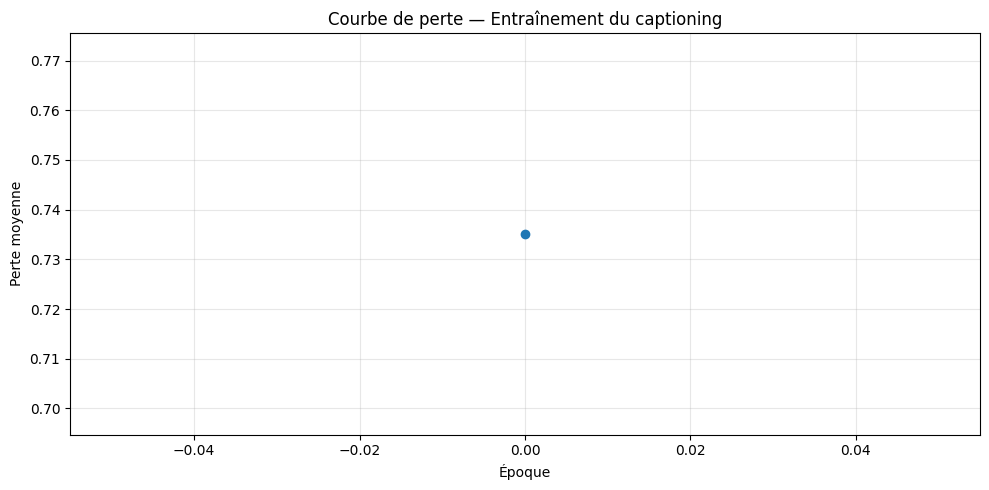

In [27]:
start_epoch = load_checkpoint()
loss_history = []

for epoch in range(start_epoch, EPOCHS):
    start_time = time.time()
    total_loss = 0.0
    batches = 0

    for batch_idx, (img_tensor, target) in enumerate(dataset):
        batch_loss, mean_batch_loss = train_step(img_tensor, target)
        total_loss += float(mean_batch_loss.cpu())
        batches += 1
        if batch_idx % 100 == 0:
            print(
                f"  Epoch {epoch + 1} | Batch {batch_idx} | "
                f"Loss: {float(batch_loss.cpu()) / target.shape[1]:.4f}"
            )

    avg_loss = total_loss / max(batches, 1)
    loss_history.append(avg_loss)
    save_checkpoint(epoch + 1)
    elapsed = time.time() - start_time
    print(
        f"Epoch {epoch + 1}/{EPOCHS} — Loss: {avg_loss:.6f} — "
        f"Durée: {elapsed:.1f}s"
    )

plt.figure(figsize=(10, 5))
plt.plot(loss_history, marker="o", linewidth=2)
plt.xlabel("Époque")
plt.ylabel("Perte moyenne")
plt.title("Courbe de perte — Entraînement du captioning")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 7.11 – Évaluation : génération de légendes

La fonction `evaluate` prend une image en entrée et génère une légende mot par mot via un **décodage glouton** (greedy decoding) :

1. Extraire les features spatiales de l'image avec InceptionV3
2. Encoder les features
3. Décoder mot par mot jusqu'au token `<end>` ou jusqu'à `MAX_LENGTH`
4. Sauvegarder les poids d'attention pour la visualisation

On enregistre les poids d'attention à chaque pas pour pouvoir visualiser sur quelles régions le modèle se concentre pour chaque mot généré.

In [28]:
attention_features_shape = 64


def evaluate(image):
    attention_plot = np.zeros((max_length, attention_features_shape))
    hidden, cell_state = decoder.reset_state(batch_size=1)
    image_array = np.expand_dims(load_image_for_inception(image)[0], axis=0)
    image_tensor = torch.as_tensor(image_array, dtype=torch.float32, device=DEVICE)
    spatial_features = build_inception_feature_extractor()(image_tensor)
    spatial_features = ops.reshape(
        spatial_features,
        (spatial_features.shape[0], -1, spatial_features.shape[-1]),
    )
    features = encoder(spatial_features)
    dec_input = torch.tensor(
        [[tokenizer.word_index["<start>"]]], dtype=torch.int64, device=DEVICE
    )
    result = []

    for i in range(max_length):
        predictions, hidden, cell_state, attention_weights = decoder(
            dec_input, features, hidden, cell_state
        )
        attention_plot[i] = ops.convert_to_numpy(
            ops.reshape(attention_weights, (-1,))
        )
        predicted_id = int(torch.argmax(predictions[0]).item())
        word = tokenizer.index_word.get(predicted_id, "<unk>")
        result.append(word)
        if word == "<end>":
            return result, attention_plot[:i + 1]
        dec_input = torch.tensor([[predicted_id]], dtype=torch.int64, device=DEVICE)

    return result, attention_plot[:len(result)]

## 7.12 – Visualisation de l'attention

La fonction `plot_attention` superpose les poids d'attention sur l'image pour chaque mot prédit. Cela permet de vérifier visuellement que le modèle « regarde » les bonnes régions de l'image pour chaque mot généré.

Chaque sous-figure montre :
- L'image originale en arrière-plan
- La carte d'attention (heatmap) en superposition
- Le mot prédit en titre

In [ ]:
def plot_attention(image_path, result, attention_plot):
    """
    Affiche l'image avec la carte d'attention pour chaque mot prédit.

    image_path     : chemin vers l'image originale
    result         : liste de mots prédits
    attention_plot : matrice (nb_mots, 64) des poids d'attention
    """
    temp_image = np.array(Image.open(image_path).convert('RGB'))

    n_words = len(result)
    n_cols = min(4, n_words)
    n_rows = (n_words + n_cols - 1) // n_cols

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(4 * n_cols, 4 * n_rows))
    if n_words == 1:
        axes = np.array([axes])
    axes = axes.flatten()

    for idx in range(n_words):
        # Reshape (64,) -> (8, 8) pour correspondre à la grille spatiale
        temp_att = attention_plot[idx].reshape(8, 8)

        ax = axes[idx]
        ax.set_title(result[idx], fontsize=14, fontweight='bold')
        img_disp = ax.imshow(temp_image)
        ax.imshow(
            temp_att, cmap='jet', alpha=0.5,
            extent=img_disp.get_extent(),
            interpolation='bilinear'
        )
        ax.axis('off')

    # Masquer les axes inutilisés
    for idx in range(n_words, len(axes)):
        axes[idx].axis('off')

    plt.suptitle("Visualisation de l'attention par mot", fontsize=16)
    plt.tight_layout()
    plt.show()


# ── Exemple d'utilisation ──
# (décommentez après entraînement)
#
# spatial_extractor = build_spatial_feature_extractor()
# test_image = 'chemin/vers/votre/image.jpg'
# result, attention_plot = evaluate(
#     test_image, encoder, decoder, spatial_extractor,
#     word_to_index, index_to_word
# )
# print('Légende prédite :', ' '.join(result))
# plot_attention(test_image, result, attention_plot)